## Assignment 3, Part 3: Non-Linear Regression with the Abalone Dataset

### Donita Monroe
### November 1, 2026

This analysis evaluates Lasso regularization and principal components regression (PCR) for predicting the number of rings in abalone. Both approaches are used to address strong correlation among the physical measurements while preserving out-of-sample predictive performance. Models are evaluated on a common validation sample, with RMSLE used as the primary comparison metric.


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, Lasso, LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_squared_log_error,
    r2_score
)

## Data Loading and Initial Inspection

The training, test, and sample-submission files are loaded directly from CSV. Initial checks verify the dimensions and structure of the data before modeling.


In [2]:
# Load the Abalone training, test, and submission-template files
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Submission shape:", sample_sub.shape)

Training shape: (90615, 10)
Test shape: (60411, 9)
Submission shape: (60411, 2)


In [3]:
# Confirm that missing-value treatment is not required
print("Training missing values:", train.isna().sum().sum())
print("Test missing values:", test.isna().sum().sum())

Training missing values: 0
Test missing values: 0


## Predictor Preparation

`id` is excluded because it is an identifier rather than a meaningful predictor, and `Rings` is defined as the response variable. The categorical `Sex` variable is converted to indicator variables. All meaningful predictors are retained initially so that Lasso and PCR can address the correlation structure directly.


In [4]:
# Prepare predictors and response
X = train.drop(columns=["id", "Rings"])

X = pd.get_dummies(
    X,
    columns=["Sex"],
    drop_first=True,
    dtype=int
)

y = train["Rings"]

print("Predictors:")
print(X.columns.tolist())

Predictors:
['Length', 'Diameter', 'Height', 'Whole weight', 'Whole weight.1', 'Whole weight.2', 'Shell weight', 'Sex_I', 'Sex_M']


## Correlation and Multicollinearity Assessment

Correlation coefficients and variance inflation factors (VIFs) are examined to evaluate redundancy among the candidate predictors. These diagnostics provide the statistical basis for using regularization and dimensionality reduction.


In [5]:
# Display the predictor correlation matrix
corr_matrix = X.corr()

corr_matrix.round(3)

,Length,Diameter,Height,Whole weight,Whole weight.1,Whole weight.2,Shell weight,Sex_I,Sex_M
Length,1.000,0.990,0.916,0.931,0.910,0.913,0.911,-0.656,0.316
Diameter,0.990,1.000,0.920,0.934,0.908,0.915,0.918,-0.665,0.319
Height,0.916,0.920,1.000,0.902,0.862,0.886,0.904,-0.645,0.302
Whole weight,0.931,0.934,0.902,1.000,0.971,0.974,0.964,-0.651,0.307
Whole weight.1,0.910,0.908,0.862,0.971,1.000,0.949,0.912,-0.619,0.300
Whole weight.2,0.913,0.915,0.886,0.974,0.949,1.000,0.937,-0.646,0.301
Shell weight,0.911,0.918,0.904,0.964,0.912,0.937,1.000,-0.648,0.301
Sex_I,-0.656,-0.665,-0.645,-0.651,-0.619,-0.646,-0.648,1.000,-0.547
Sex_M,0.316,0.319,0.302,0.307,0.300,0.301,0.301,-0.547,1.000


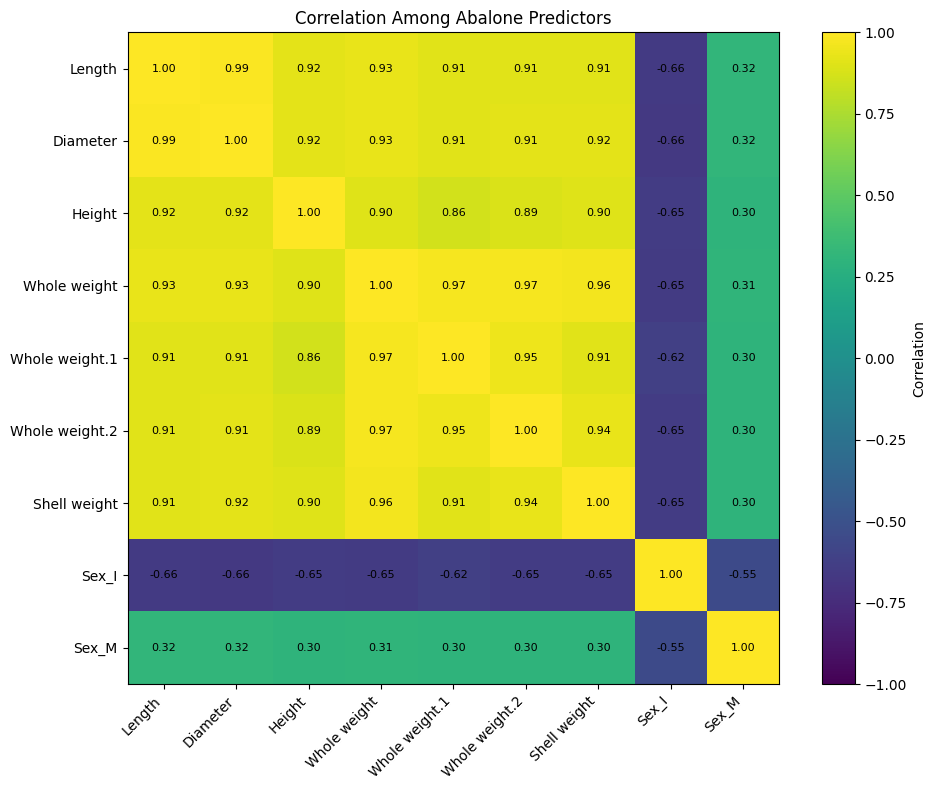

In [6]:
# Visualize predictor correlations
fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))

ax.set_xticklabels(
    corr_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(heatmap, ax=ax, label="Correlation")
plt.title("Correlation Among Abalone Predictors")
plt.tight_layout()
plt.show()

In [7]:
# Calculate VIF values for the full predictor set
X_vif = sm.add_constant(X.astype(float))

vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_results = (
    vif_results[vif_results["Variable"] != "const"]
    .sort_values("VIF", ascending=False)
)

vif_results

,Variable,VIF
4,Whole weight,69.242348
2,Diameter,54.291324
1,Length,51.208712
5,Whole weight.1,21.463228
6,Whole weight.2,20.067845
7,Shell weight,18.339175
3,Height,7.813579
8,Sex_I,2.387746
9,Sex_M,1.442002


### Diagnostic Interpretation

The physical measurements show substantial overlap, particularly among `Whole weight`, `Diameter`, `Length`, and the component weight measures. The VIF results confirm that several predictors contain highly redundant information.

Lasso and PCR address this problem differently. Lasso shrinks regression coefficients and can reduce weak predictors toward zero, while PCR replaces the correlated predictors with a smaller set of uncorrelated principal components.


## Validation Design

The data are divided into an 80% training sample and a 20% validation sample using `random_state=42`. Predictors are standardized using the training data because both Lasso penalties and principal component analysis depend on variable scale.


In [8]:
# Create an 80/20 training-validation split
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Standardize predictors using the training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

Training shape: (72492, 9)
Validation shape: (18123, 9)


In [9]:
# Define model evaluation metrics
def evaluate_model(y_true, y_pred):

    y_pred_nonnegative = np.maximum(y_pred, 0)

    return {
        "RMSLE": np.sqrt(
            mean_squared_log_error(
                y_true,
                y_pred_nonnegative
            )
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
        "R2": r2_score(
            y_true,
            y_pred
        )
    }

## Model 1: Lasso Regression

Lasso regression applies an $L_1$ penalty to the regression coefficients. The penalty parameter is selected by cross-validation, allowing the data to determine the degree of coefficient shrinkage. The resulting coefficient pattern is used to evaluate the relative contribution of the original predictors.


In [10]:
# Fit Lasso using cross-validation to choose the penalty
lasso_model = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000
)

lasso_model.fit(
    X_train_scaled,
    y_train
)

lasso_pred = lasso_model.predict(
    X_valid_scaled
)

print("Selected alpha:", lasso_model.alpha_)

Selected alpha: 0.0022063763304642795


In [11]:
# Evaluate Lasso on the validation data
lasso_results = evaluate_model(
    y_valid,
    lasso_pred
)

pd.Series(
    lasso_results,
    name="Lasso"
)

RMSLE    0.166705
RMSE     2.024769
MAE      1.392557
R2       0.600901
Name: Lasso, dtype: float64

In [12]:
# Examine the standardized Lasso coefficients
lasso_coefficients = pd.DataFrame({
    "Predictor": X.columns,
    "Coefficient": lasso_model.coef_
})

lasso_coefficients["Absolute Coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

lasso_coefficients = (
    lasso_coefficients
    .sort_values("Absolute Coefficient", ascending=False)
    .reset_index(drop=True)
)

lasso_coefficients

,Predictor,Coefficient,Absolute Coefficient
0,Whole weight.1,-3.140700,3.140700
1,Shell weight,2.778902,2.778902
2,Whole weight,1.489079,1.489079
3,Height,0.753473,0.753473
4,Whole weight.2,-0.604988,0.604988
5,Diameter,0.572922,0.572922
6,Sex_I,-0.340432,0.340432
7,Sex_M,-0.006242,0.006242
8,Length,-0.004216,0.004216


### Lasso Results

Cross-validation selected an alpha of approximately **0.00221**. All nine predictors retained nonzero coefficients, although `Length` and `Sex_M` were very close to zero relative to the remaining variables. Their small coefficients indicate limited unique predictive contribution after the correlated physical measurements are considered.

Validation performance was RMSLE = **0.16670**, RMSE = **2.0248**, MAE = **1.3926**, and $R^2$ = **0.6009**.


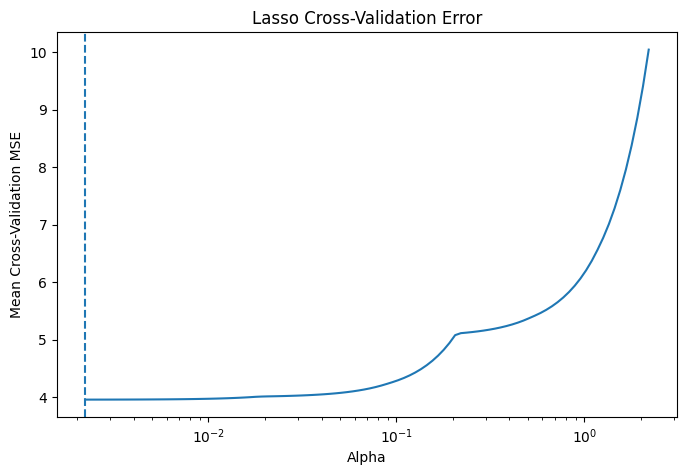

In [13]:
# Plot mean cross-validation error across penalty values
mean_cv_mse = lasso_model.mse_path_.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.semilogx(
    lasso_model.alphas_,
    mean_cv_mse
)

plt.axvline(
    lasso_model.alpha_,
    linestyle="--"
)

plt.xlabel("Alpha")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Lasso Cross-Validation Error")
plt.show()

## Lasso Residual Diagnostics

Residual-versus-predicted and Q-Q plots are used to evaluate model form, residual spread, and residual distribution. Independence is considered reasonable because the observations represent separate cross-sectional records and the validation sample was created through random splitting.


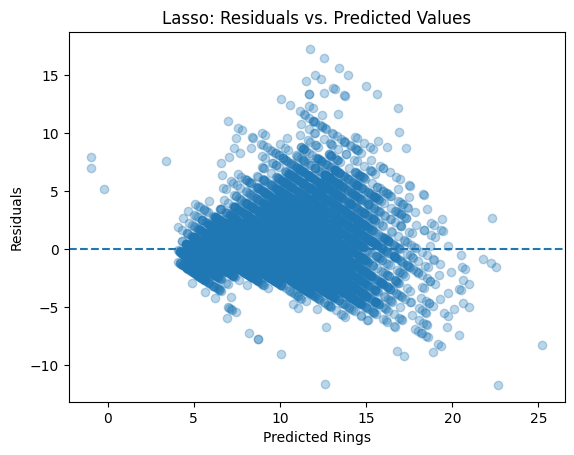

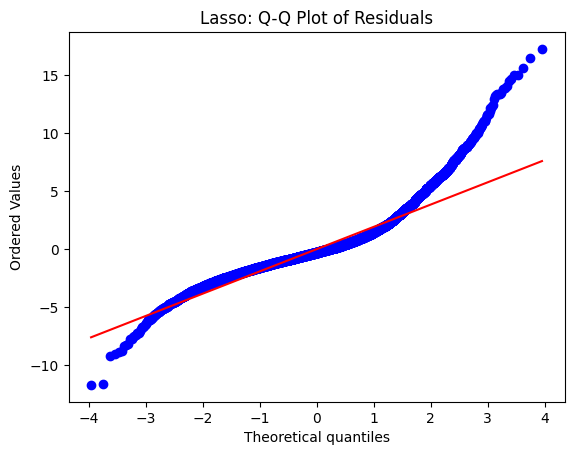

In [14]:
# Examine Lasso residuals
lasso_residuals = y_valid - lasso_pred

plt.scatter(
    lasso_pred,
    lasso_residuals,
    alpha=0.3
)

plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Rings")
plt.ylabel("Residuals")
plt.title("Lasso: Residuals vs. Predicted Values")
plt.show()

stats.probplot(
    lasso_residuals,
    dist="norm",
    plot=plt
)

plt.title("Lasso: Q-Q Plot of Residuals")
plt.show()

### Diagnostic Interpretation

The residual-versus-predicted plot shows some structure and changing spread across the fitted range, indicating that constant variance is not fully satisfied. The Q-Q plot also departs from the reference line in the tails. Lasso improves coefficient stability under multicollinearity, but regularization does not by itself correct nonlinearity, heteroscedasticity, or departures from residual normality.


## Model 2: Principal Components Regression

Principal components regression addresses multicollinearity by transforming the standardized predictors into orthogonal principal components and fitting linear regression to those components. Models using one through nine components are compared using validation RMSLE to determine how much dimensionality is needed for prediction.


In [15]:
# Compare PCR models using 1 through 9 principal components
pcr_results = []

for n_components in range(1, X_train.shape[1] + 1):

    pca = PCA(n_components=n_components)

    X_train_pca = pca.fit_transform(
        X_train_scaled
    )

    X_valid_pca = pca.transform(
        X_valid_scaled
    )

    pcr_model = LinearRegression()

    pcr_model.fit(
        X_train_pca,
        y_train
    )

    pcr_pred = pcr_model.predict(
        X_valid_pca
    )

    results = evaluate_model(
        y_valid,
        pcr_pred
    )

    pcr_results.append({
        "Components": n_components,
        **results
    })

pcr_results = pd.DataFrame(pcr_results)

pcr_results

,Components,RMSLE,RMSE,MAE,R2
0,1,0.195888,2.448555,1.700371,0.416354
1,2,0.195887,2.448414,1.700324,0.416421
2,3,0.194723,2.428485,1.691259,0.425882
3,4,0.187260,2.347779,1.635558,0.463408
4,5,0.177907,2.199568,1.518802,0.529018
5,6,0.166554,2.037591,1.399946,0.595830
6,7,0.166770,2.037178,1.399660,0.595994
7,8,0.166777,2.024225,1.392768,0.601115
8,9,0.166774,2.023690,1.393015,0.601326


Selected number of components: 6


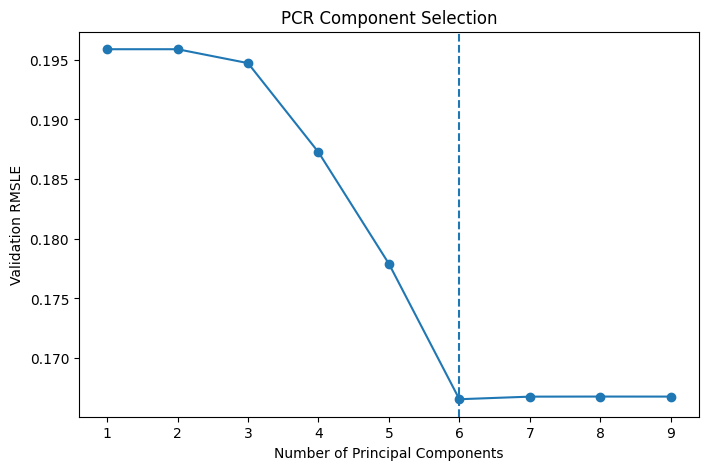

In [16]:
# Select the component count with the lowest validation RMSLE
best_n = int(
    pcr_results.loc[
        pcr_results["RMSLE"].idxmin(),
        "Components"
    ]
)

print("Selected number of components:", best_n)

plt.figure(figsize=(8, 5))

plt.plot(
    pcr_results["Components"],
    pcr_results["RMSLE"],
    marker="o"
)

plt.axvline(
    best_n,
    linestyle="--"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Validation RMSLE")
plt.title("PCR Component Selection")
plt.show()

In [17]:
# Fit the selected PCR model
pca_final = PCA(
    n_components=best_n
)

X_train_pca = pca_final.fit_transform(
    X_train_scaled
)

X_valid_pca = pca_final.transform(
    X_valid_scaled
)

pcr_model = LinearRegression()

pcr_model.fit(
    X_train_pca,
    y_train
)

pcr_pred = pcr_model.predict(
    X_valid_pca
)

pcr_model_results = evaluate_model(
    y_valid,
    pcr_pred
)

pd.Series(
    pcr_model_results,
    name="PCR"
)

RMSLE    0.166554
RMSE     2.037591
MAE      1.399946
R2       0.595830
Name: PCR, dtype: float64

### PCR Results

The validation comparison selected **six principal components**. This reduced the nine correlated predictors to six uncorrelated dimensions while preserving nearly all of the predictive information needed for the response.

Validation performance was RMSLE = **0.16655**, RMSE = **2.0376**, MAE = **1.3999**, and $R^2$ = **0.5958**.


## PCR Residual Diagnostics

The same residual diagnostics are examined for PCR so that its assumptions and limitations can be evaluated on the same basis as the Lasso model.


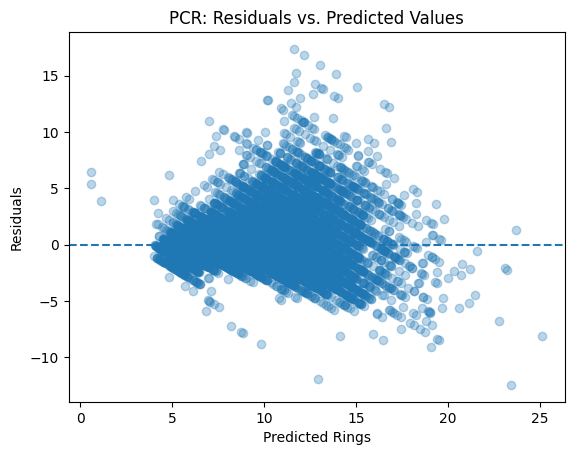

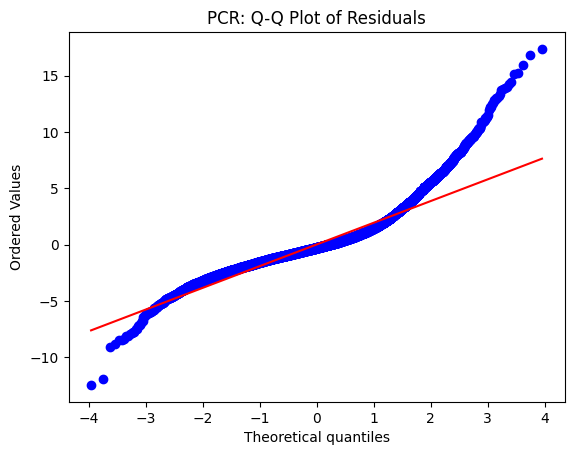

In [18]:
# Examine PCR residuals
pcr_residuals = y_valid - pcr_pred

plt.scatter(
    pcr_pred,
    pcr_residuals,
    alpha=0.3
)

plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Rings")
plt.ylabel("Residuals")
plt.title("PCR: Residuals vs. Predicted Values")
plt.show()

stats.probplot(
    pcr_residuals,
    dist="norm",
    plot=plt
)

plt.title("PCR: Q-Q Plot of Residuals")
plt.show()

### Diagnostic Interpretation

PCR eliminates correlation among the transformed predictors, but the residual plots still show some changing spread and tail departures. This indicates that removing predictor redundancy does not fully capture every nonlinear relationship or distributional feature in `Rings`.


## Validation Model Comparison

Both models are evaluated on the same validation observations. RMSLE is emphasized as the primary predictive metric, while RMSE, MAE, and $R^2$ provide additional context for model performance.


In [19]:
# Compare Lasso and PCR
model_comparison = pd.DataFrame({
    "Lasso": lasso_results,
    "PCR": pcr_model_results
}).T

model_comparison

,RMSLE,RMSE,MAE,R2
Lasso,0.166705,2.024769,1.392557,0.600901
PCR,0.166554,2.037591,1.399946,0.595830


### Comparative Interpretation

Lasso and PCR produced very similar validation performance. PCR achieved a slightly lower RMSLE, while Lasso produced slightly better RMSE, MAE, and $R^2$. The small differences suggest that both approaches handled the correlated predictor structure effectively. Lasso retains the advantage of direct predictor-level interpretation, whereas PCR represents the same information through a smaller set of uncorrelated components.


## Final Model Fitting and Prediction

Each model is refit using the complete labeled training dataset. The fitted preprocessing steps are then applied to `test.csv`, and predictions are written in the structure defined by `sample_submission.csv`.


In [20]:
# Prepare the test predictors using the training feature structure
X_test = test.drop(columns=["id"])

X_test = pd.get_dummies(
    X_test,
    columns=["Sex"],
    drop_first=True,
    dtype=int
)

X_test = X_test.reindex(
    columns=X.columns,
    fill_value=0
)

print("Full training shape:", X.shape)
print("Test shape:", X_test.shape)
print("Columns match:", X.columns.tolist() == X_test.columns.tolist())

Full training shape: (90615, 9)
Kaggle test shape: (60411, 9)
Columns match: True


In [21]:
# Refit Lasso using the complete training dataset
full_scaler_lasso = StandardScaler()

X_full_scaled_lasso = full_scaler_lasso.fit_transform(X)
X_test_scaled_lasso = full_scaler_lasso.transform(X_test)

lasso_final = Lasso(
    alpha=lasso_model.alpha_,
    max_iter=100000
)

lasso_final.fit(
    X_full_scaled_lasso,
    y
)

kaggle_pred_lasso = lasso_final.predict(
    X_test_scaled_lasso
)

kaggle_pred_lasso = np.clip(
    kaggle_pred_lasso,
    0,
    None
)

submission_lasso = sample_sub.copy()
submission_lasso["Rings"] = kaggle_pred_lasso

submission_lasso.to_csv(
    "submission_assignment3_lasso.csv",
    index=False
)

submission_lasso.head()

,id,Rings
0,90615,8.661681
1,90616,10.045043
2,90617,10.346720
3,90618,10.854434
4,90619,7.759604


In [22]:
# Refit PCR using the complete training dataset
full_scaler_pcr = StandardScaler()

X_full_scaled_pcr = full_scaler_pcr.fit_transform(X)
X_test_scaled_pcr = full_scaler_pcr.transform(X_test)

pca_full = PCA(
    n_components=best_n
)

X_full_pca = pca_full.fit_transform(
    X_full_scaled_pcr
)

X_test_pca = pca_full.transform(
    X_test_scaled_pcr
)

pcr_final = LinearRegression()

pcr_final.fit(
    X_full_pca,
    y
)

kaggle_pred_pcr = pcr_final.predict(
    X_test_pca
)

kaggle_pred_pcr = np.clip(
    kaggle_pred_pcr,
    0,
    None
)

submission_pcr = sample_sub.copy()
submission_pcr["Rings"] = kaggle_pred_pcr

submission_pcr.to_csv(
    "submission_assignment3_pcr.csv",
    index=False
)

submission_pcr.head()

,id,Rings
0,90615,8.803692
1,90616,10.210797
2,90617,10.345726
3,90618,10.613844
4,90619,7.742197


In [23]:
# Verify the final prediction files
submission_check = pd.DataFrame({
    "Model": ["Lasso", "PCR"],
    "Rows": [
        len(submission_lasso),
        len(submission_pcr)
    ],
    "Missing Predictions": [
        submission_lasso["Rings"].isna().sum(),
        submission_pcr["Rings"].isna().sum()
    ],
    "Minimum Prediction": [
        submission_lasso["Rings"].min(),
        submission_pcr["Rings"].min()
    ],
    "Maximum Prediction": [
        submission_lasso["Rings"].max(),
        submission_pcr["Rings"].max()
    ]
})

submission_check

,Model,Rows,Missing Predictions,Minimum Prediction,Maximum Prediction
0,Lasso,60411,0,0.000000,29.001240
1,PCR,60411,0,0.355513,29.865958


## Kaggle Results

Both finalized models were successfully evaluated on the Abalone competition data using RMSLE, where lower values indicate better predictive performance.

### Lasso Regression

- **Public RMSLE:** 0.16441
- **Private RMSLE:** 0.16503

### Principal Components Regression

- **Public RMSLE:** 0.16457
- **Private RMSLE:** 0.16376

The competition results were closely matched. Lasso achieved the slightly lower public score, while PCR achieved the lower private score.


## Final Model Comparison

| Model | Validation RMSLE | RMSE | MAE | $R^2$ | Kaggle Public RMSLE | Kaggle Private RMSLE |
|---|---:|---:|---:|---:|---:|---:|
| Lasso | 0.166705 | 2.024769 | 1.392557 | 0.600901 | 0.16441 | 0.16503 |
| PCR | 0.166554 | 2.037591 | 1.399946 | 0.595830 | 0.16457 | 0.16376 |

The two models produced very similar predictive performance. PCR achieved the lower validation RMSLE and the lower private Kaggle score, while Lasso produced slightly better RMSE, MAE, $R^2$, and public Kaggle RMSLE. Because the differences were small, neither model dominated across every measure. PCR showed a slight advantage on the primary RMSLE metric in the validation and private competition results, while Lasso retained the advantage of direct predictor-level interpretation.


## Conclusion

Lasso and PCR provided two effective approaches to the substantial multicollinearity among the Abalone physical measurements. Lasso used coefficient shrinkage to evaluate the unique contribution of the original predictors, while PCR reduced the predictor space to six orthogonal components. Their validation and Kaggle results were closely matched. PCR produced the lowest validation RMSLE and private competition score, whereas Lasso performed slightly better on RMSE, MAE, $R^2$, and the public competition score. Overall, the analysis demonstrates that regularization and dimension reduction can address correlated predictors through different statistical strategies while maintaining comparable predictive performance.
